# Explainability: Best Models for each Configuration

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
shap.initjs()

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_train = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_train.csv')
df_test = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_test.csv')

In [3]:
n_classes = 3

In [4]:
lab_encoder = joblib.load('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/3. Data Understanding and Prep/label_encoder.pkl')

1. 

In [5]:
cols_to_drop = df_train.filter(regex=r"2020|2021|2022").columns.tolist()
df_train = df_train.drop(cols_to_drop, axis = 1)
df_test = df_test.drop(cols_to_drop, axis = 1)

In [6]:
y_test = df_test['target']
x_test = df_test.drop('target', axis=1)

In [7]:
y = df_train['target']
X = df_train.drop('target', axis = 1)

In [8]:
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

In [9]:
columns_to_scale = df_train.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale] = scaler.transform(x_val[columns_to_scale])
x_test[columns_to_scale] = scaler.transform(x_test[columns_to_scale])

In [10]:
x_train.shape

(344, 274)

2. Caricamento dei modelli migliori con e senza city: Per la classificazione ad un anno il modello migliore è la logistic regression

In [11]:
model_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli ad un anno con city/log_reg_due_city.pkl')
#model_no_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli ad un anno senza city/_rf_tesi_uno_nocity.pkl')

3. SHAP

3.1 City

In [12]:
x_train = x_train.astype(np.float64)
x_val = x_val.astype(np.float64)
x_test = x_test.astype(np.float64)

feature_names = x_train.columns.tolist()

In [13]:
explainer_city = shap.LinearExplainer(model_city, x_train)
shap_values_city = explainer_city(x_train)

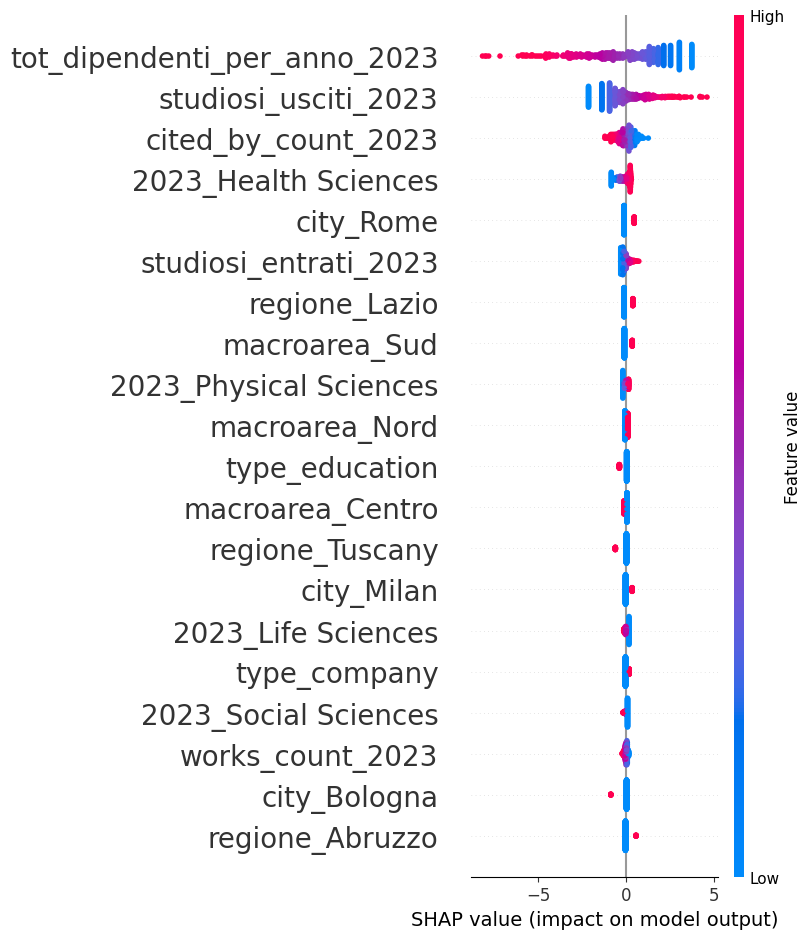

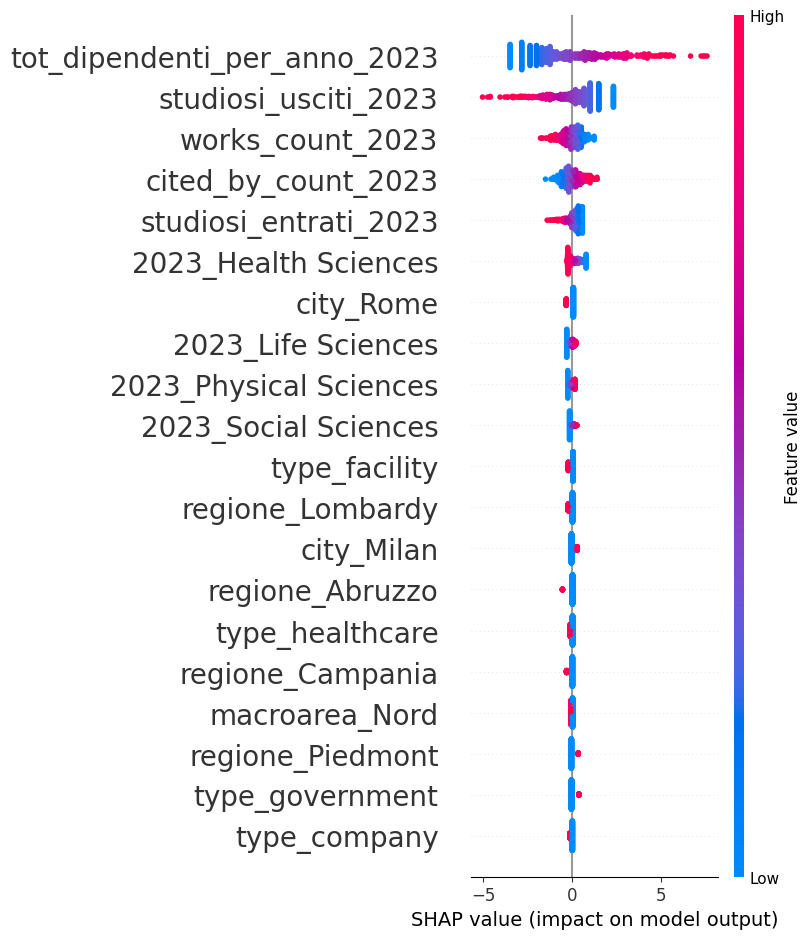

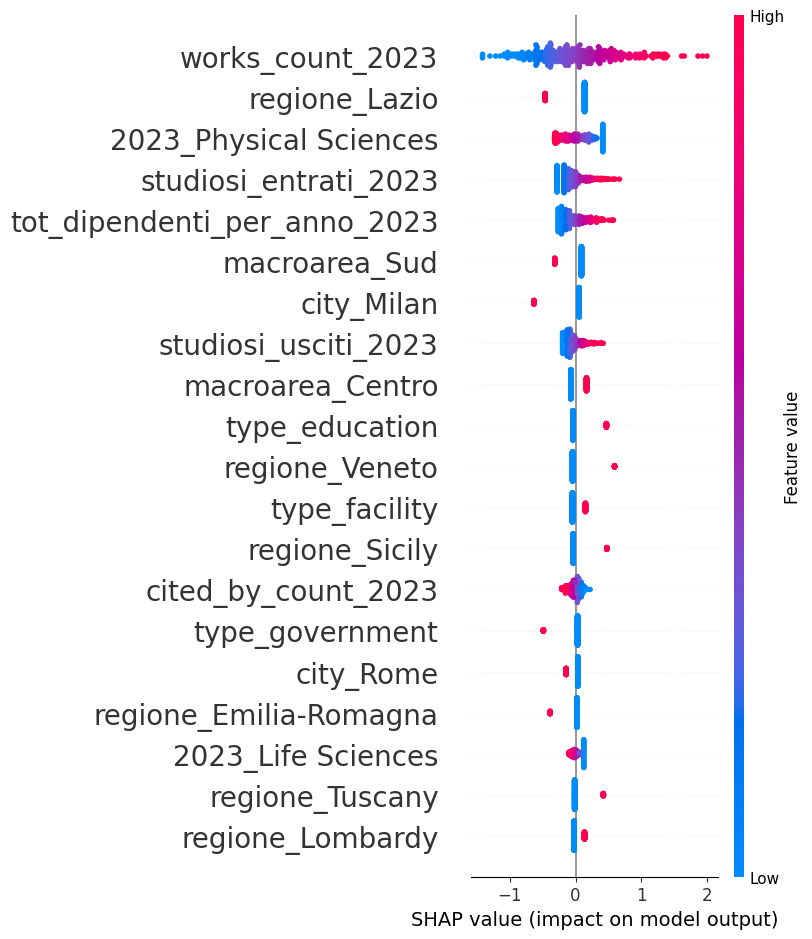

In [14]:
# for i in range(n_classes):
#     shap.summary_plot(
#         shap_values_city[:, :, i],
#         x_train,
#         show=True
#     )

for i in range(n_classes):
    plt.figure()
    shap.summary_plot(
        shap_values_city[:, :, i],
        x_train,
        show=False  # ← importante: non mostrare subito
    )
    
    ax = plt.gca()
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=20)  # label features (asse Y)
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)             # label asse X
    ax.tick_params(axis='x', labelsize=12)                  # tick asse X
    
    plt.tight_layout()
    plt.savefig(f"classe_{i}.png", dpi=150, bbox_inches='tight')
    plt.show()

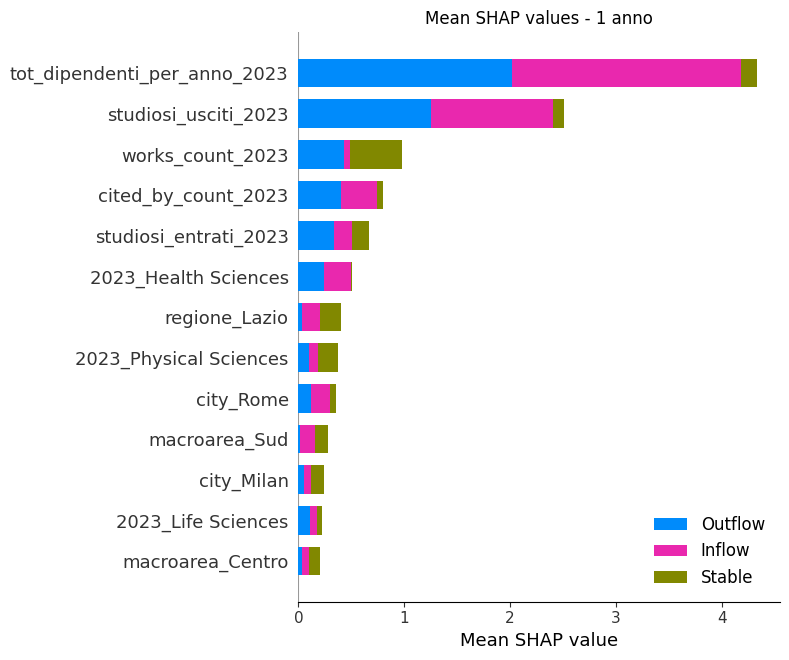

In [15]:
shap.summary_plot(shap_values_city, x_train, plot_type="bar", max_display=13, show= False, class_names = ['Inflow', 'Outflow', 'Stable'] )
plt.xlabel("Mean SHAP value")
plt.title("Mean SHAP values - 1 anno")
plt.tight_layout()
plt.show()

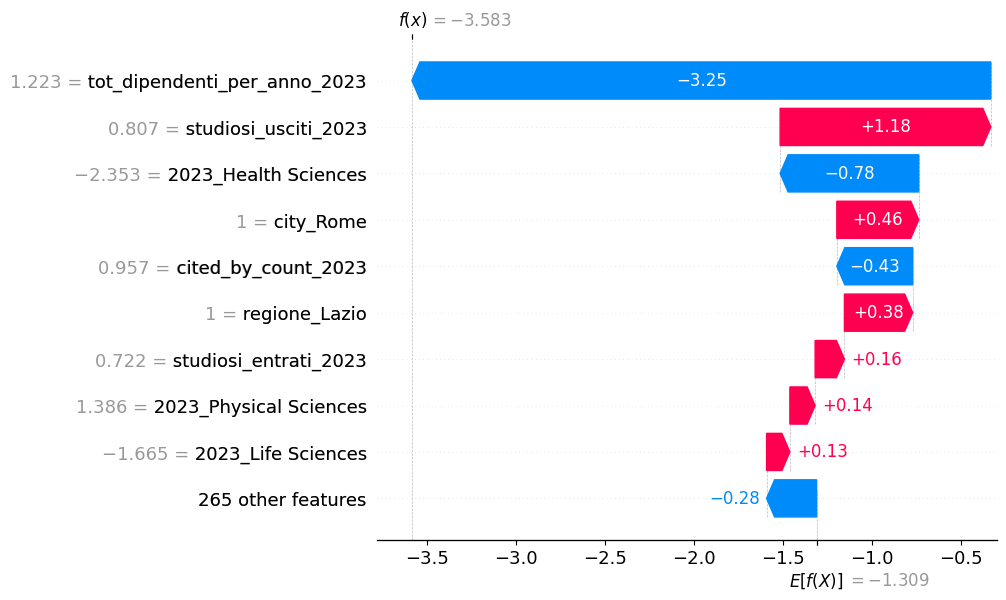

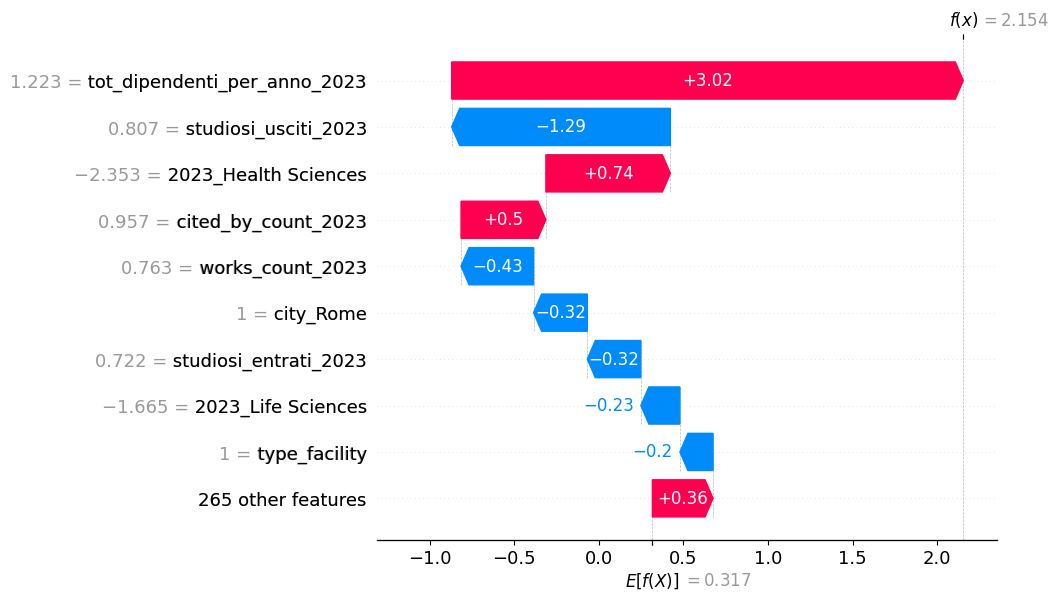

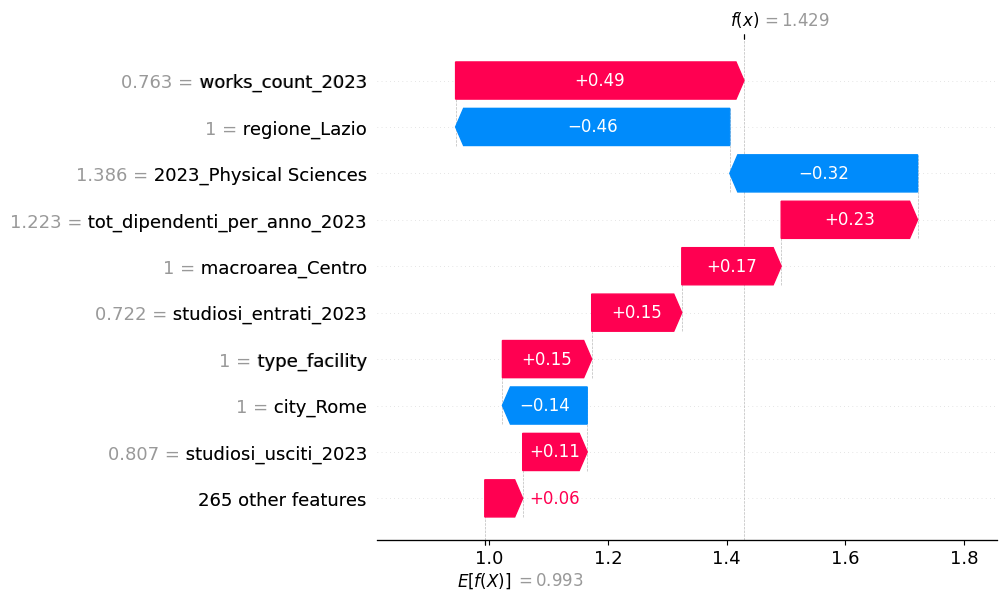

In [16]:
for i in range(n_classes):
    shap.waterfall_plot(shap_values_city[0, :, i])

4.1 Ri Allenamento del modello

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [19]:
# Estrai i valori dall'oggetto Explanation
shap_vals = (
    shap_values_city.values
    if hasattr(shap_values_city, "values")
    else np.stack(shap_values_city, axis=2)
)

# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
shap_importance_city = np.mean(np.abs(shap_vals), axis=(0, 2))

In [20]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": shap_importance_city
}).sort_values("mean_abs_shap", ascending=False)

top_features = feature_importance.head(13)
print(top_features)

                          feature  mean_abs_shap
2    tot_dipendenti_per_anno_2023       1.444497
3            studiosi_usciti_2023       0.836683
0                works_count_2023       0.325922
1             cited_by_count_2023       0.267468
4           studiosi_entrati_2023       0.223274
5            2023_Health Sciences       0.169115
20                  regione_Lazio       0.134624
8          2023_Physical Sciences       0.125717
222                     city_Rome       0.118194
35                  macroarea_Sud       0.093827
166                    city_Milan       0.080619
6              2023_Life Sciences       0.073517
32               macroarea_Centro       0.067665


Proviamo quantità diverse di features e compariamo i risultati in termini di accuracy ad f1 score

In [21]:
log_reg_params = [
    {
        'solver': ['lbfgs', 'newton-cg'],
        'C': [0.01, 0.1, 1],
        'class_weight': ['balanced'],
        'max_iter': [300, 1000],
        'penalty': ['l2']
    },
    {
        'solver': ['sag', 'saga'],
        'C': [0.01, 0.1, 1],
        'class_weight': ['balanced'],
        'max_iter': [1000, 5000],
        'penalty': ['l2']
    }
]


grid_log_reg = GridSearchCV(LogisticRegression(),
                            log_reg_params, 
                            cv = cv, 
                            scoring = 'f1_macro',
                            verbose=1,
                            )

validation_dict = {}

In [22]:
def different_idx(shap_values, results_dict, X_train_df, X_val_df, y_train, y_val):
    
    shap_vals = (
        shap_values.values
        if hasattr(shap_values, "values")
        else np.stack(shap_values, axis=2)
    )
    shap_importance = np.mean(np.abs(shap_vals), axis=(0, 2))
    
    best_f1       = -1
    best_model    = None
    best_X_train  = None
    best_X_val    = None
    best_features = None
    
    for i in range(10, 20):
        top_idx      = np.argsort(shap_importance)[::-1][:i]
        top_features = np.array(X_train_df.columns)[top_idx]
        
        X_train_top = X_train_df[top_features]
        X_val_top   = X_val_df[top_features]
        
        grid_log_reg.fit(X_train_top, y_train)
        lr = grid_log_reg.best_estimator_
        
        y_pred = lr.predict(X_val_top)
        acc = accuracy_score(y_val, y_pred)
        f1  = f1_score(y_val, y_pred, average="macro")
        
        results_dict[i] = {
            'n_features' : i,
            'accuracy'   : round(acc, 4),
            'f1'         : round(f1, 4),
            'best_params': grid_log_reg.best_params_
        }
        
        if f1 > best_f1:
            best_f1       = f1
            best_model    = lr
            best_X_train  = X_train_top
            best_X_val    = X_val_top
            best_features = top_features
    
    return results_dict, best_model, best_X_train, best_X_val, best_features

results = {}
# Chiamata
results, log_reg_model, new_x_train, new_x_val, top_features = different_idx(
    shap_values_city, results,
    X_train_df=x_train, X_val_df=x_val,
    y_train=y_train, y_val=y_val
)

# Ora new_x_val ha esattamente le features su cui log_reg_model è stato fittato
y_pred_city = log_reg_model.predict(new_x_val)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

... (10 outputs left out)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

In [23]:
df_results = pd.DataFrame(results).T.reset_index(drop=True)
df_results = df_results.sort_values(by='f1', ascending=False)

In [24]:
df_results

,n_features,accuracy,f1,best_params
3,13,0.6043,0.5381,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
1,11,0.6043,0.5357,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
0,10,0.6043,0.5347,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
4,14,0.5957,0.5345,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
5,15,0.587,0.5259,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
6,16,0.5826,0.5227,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
2,12,0.587,0.5225,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
8,18,0.5826,0.5199,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
7,17,0.5739,0.5168,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
9,19,0.5696,0.506,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."


In [25]:
X_full = pd.concat([x_train, x_val])
y_full = pd.concat([y_train, y_val])

X_full_top = X_full[top_features]

final_model = LogisticRegression(**log_reg_model.get_params())
final_model.fit(X_full_top, y_full)

/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multicl

In [26]:
print('Classification Report per Logistic Regression')
print(classification_report(y_val, y_pred_city))
print(f'Accuracy della Logistic Regression: {accuracy_score(y_val, y_pred_city)}')
print(f'F1 Score della Logistic Regression: {f1_score(y_val, y_pred_city, average="macro")}')

Classification Report per Logistic Regression
              precision    recall  f1-score   support

           0       0.33      0.62      0.43        21
           1       0.38      0.67      0.48        48
           2       0.90      0.58      0.71       161

    accuracy                           0.60       230
   macro avg       0.53      0.62      0.54       230
weighted avg       0.73      0.60      0.63       230

Accuracy della Logistic Regression: 0.6043478260869565
F1 Score della Logistic Regression: 0.5380664776695837


5.1 Evaluation

In [27]:
y_test_pred = final_model.predict(x_test[top_features])
    
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
test_f1_macro = f1_score(y_test, y_test_pred, average='macro')

In [28]:
print(classification_report(y_test, y_test_pred, 
                                  target_names=lab_encoder.classes_))

              precision    recall  f1-score   support

      inflow       0.25      0.71      0.37        38
     outflow       0.45      0.51      0.48        90
      stable       0.85      0.58      0.69       256

    accuracy                           0.58       384
   macro avg       0.52      0.60      0.51       384
weighted avg       0.70      0.58      0.61       384



3.2 Senza city

In [29]:
df_train_no_city = df_train.loc[:, ~df_train.columns.str.contains(r'city')]
df_test_no_city = df_test.loc[:, ~df_test.columns.str.contains(r'city')]

In [30]:
y_test_no_city = df_test_no_city['target']
x_test_no_city = df_test_no_city.drop('target', axis=1)

In [31]:
y_nocity = df_train_no_city['target']
X_nocity = df_train_no_city.drop('target', axis = 1)

In [32]:
x_train, x_val, y_train, y_val = train_test_split(X_nocity, y_nocity, test_size=0.4, random_state=42, stratify=y_nocity)

In [33]:
columns_to_scale = df_train_no_city.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale] = scaler.transform(x_val[columns_to_scale])
df_test_no_city[columns_to_scale] = scaler.transform(df_test_no_city[columns_to_scale])

/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_1556/4128192901.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_no_city[columns_to_scale] = scaler.transform(df_test_no_city[columns_to_scale])


In [34]:
explainer_nocity = shap.TreeExplainer(model_no_city)
shap_values_nocity = explainer_nocity(x_val)

NameError: name 'model_no_city' is not defined


--- Classe 0 ---


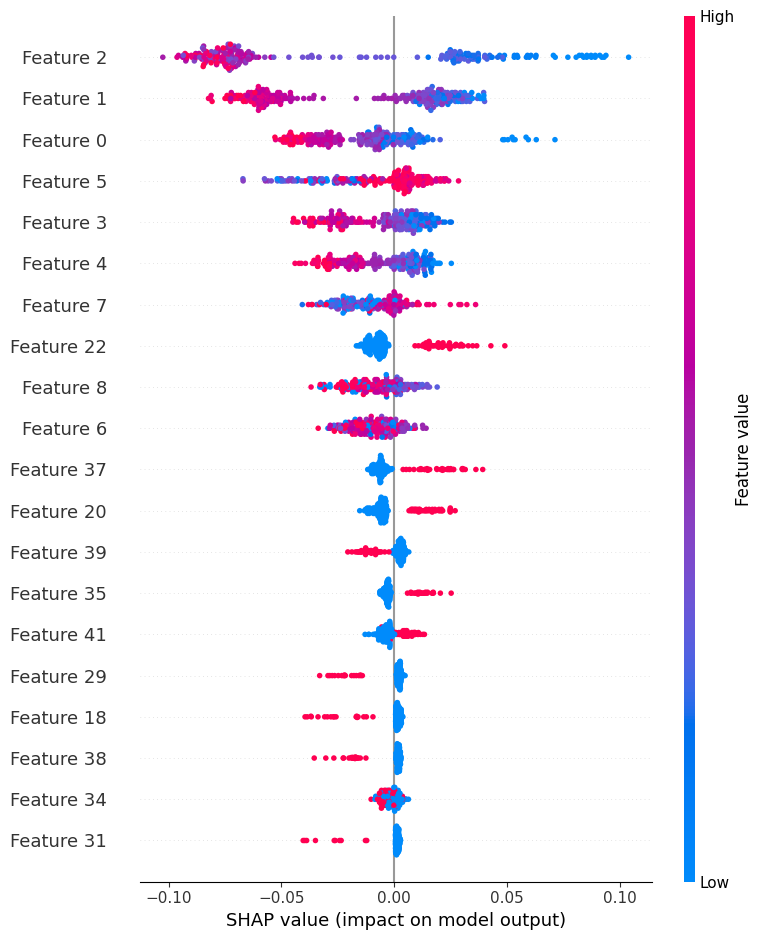


--- Classe 1 ---


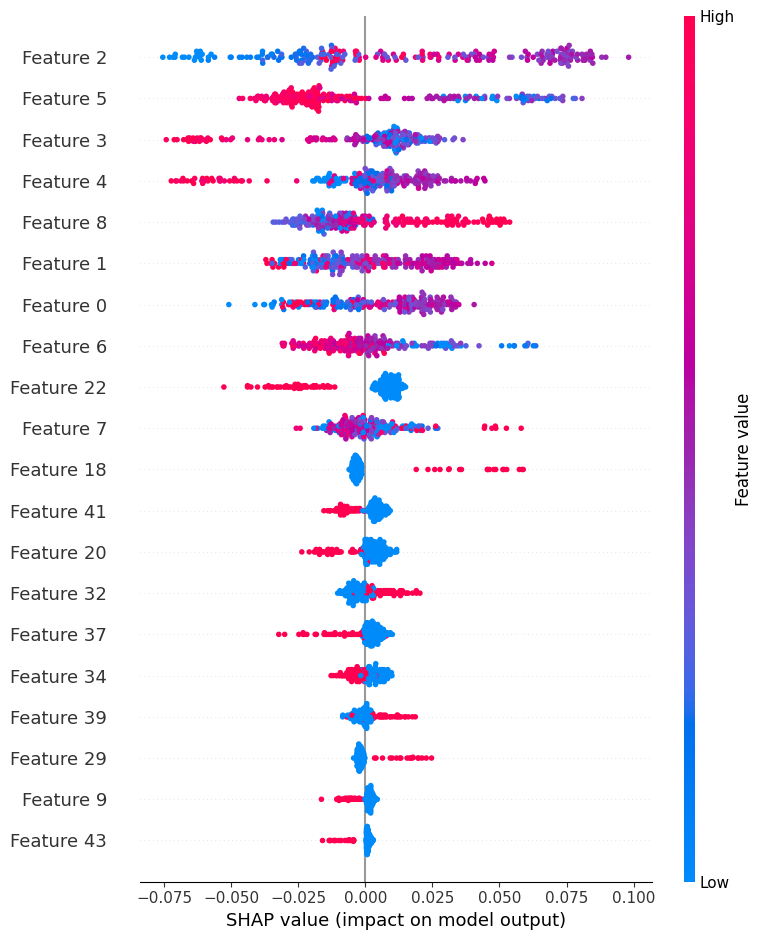


--- Classe 2 ---


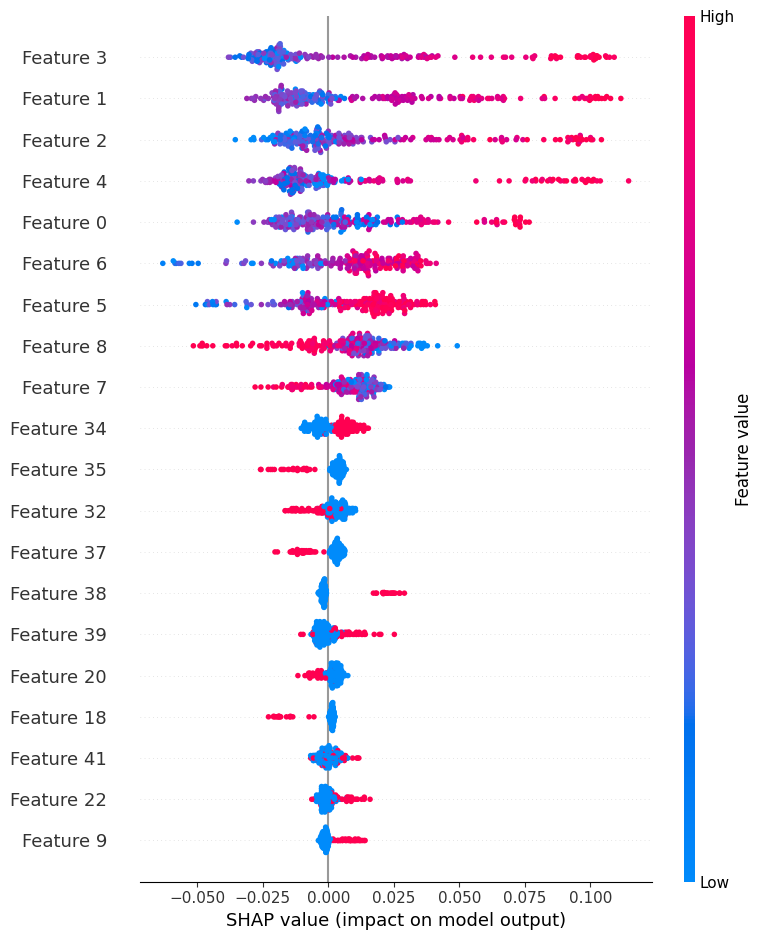

In [ ]:
shap_values_float_nocity = shap_values_nocity.values.astype(np.float64)
x_test_float_nocity = np.array(x_val, dtype=np.float64)

for i in range(n_classes):
    print(f"\n--- Classe {i} ---")
    shap.summary_plot(shap_values_float_nocity[:, :, i], x_test_float_nocity, show=True)

In [ ]:
lab_encoder.classes_

array(['inflow', 'outflow', 'stable'], dtype=object)

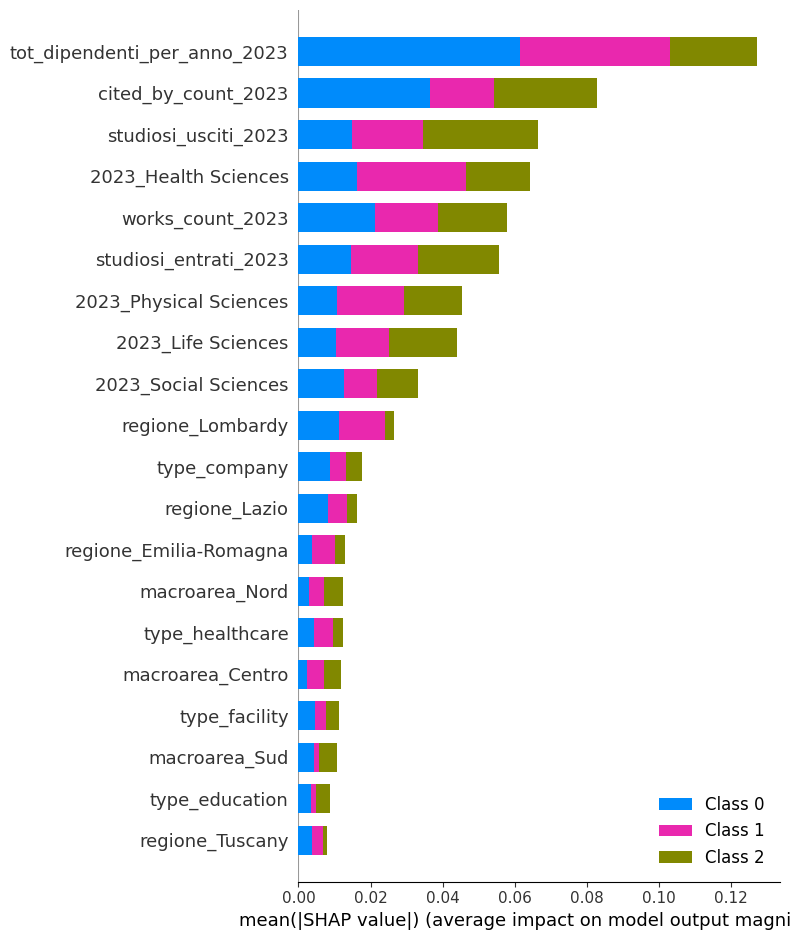

In [ ]:
shap.summary_plot(shap_values_float_nocity, x_val, plot_type="bar")

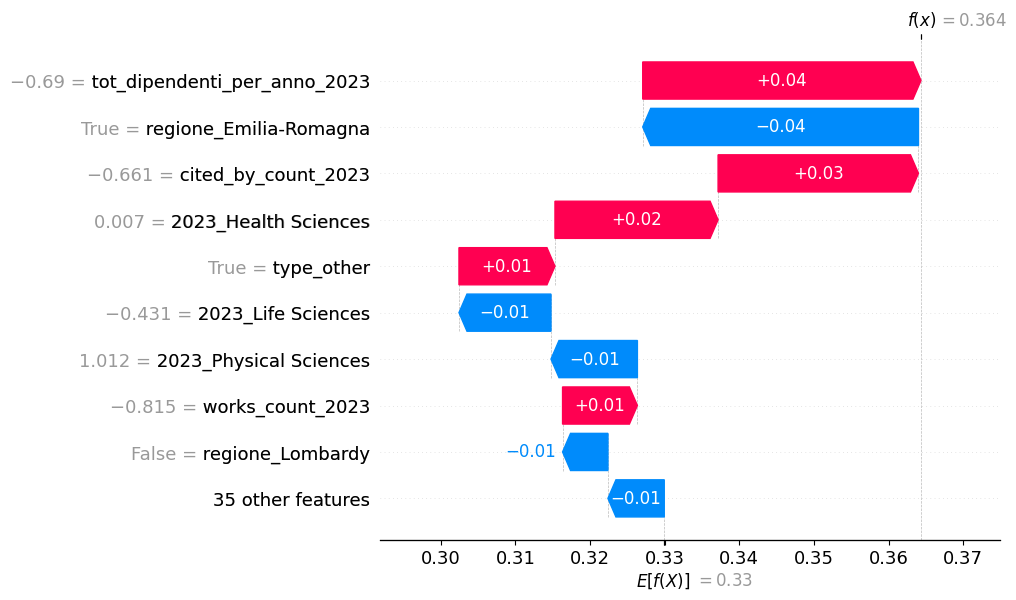

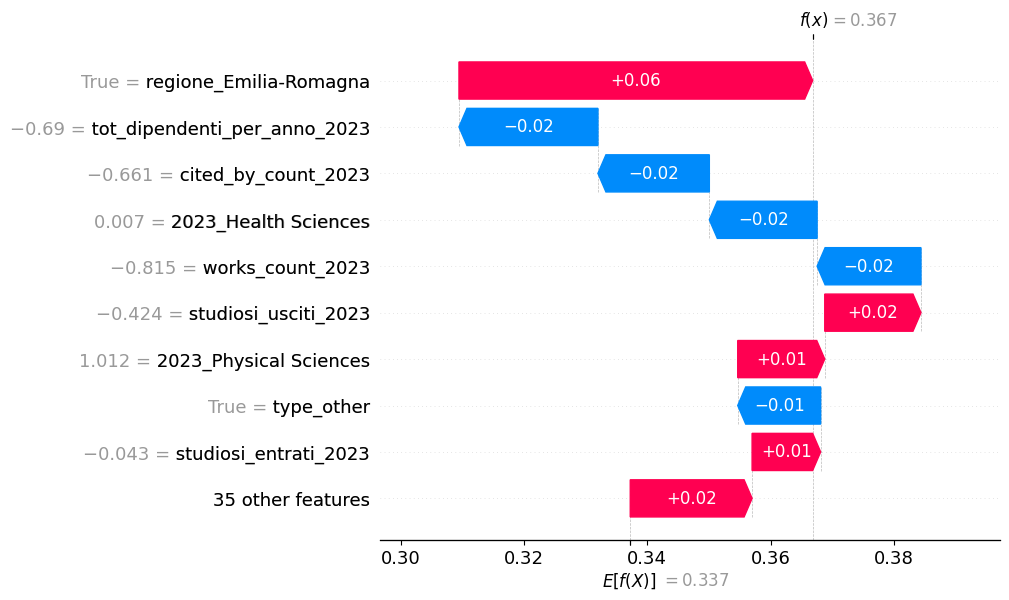

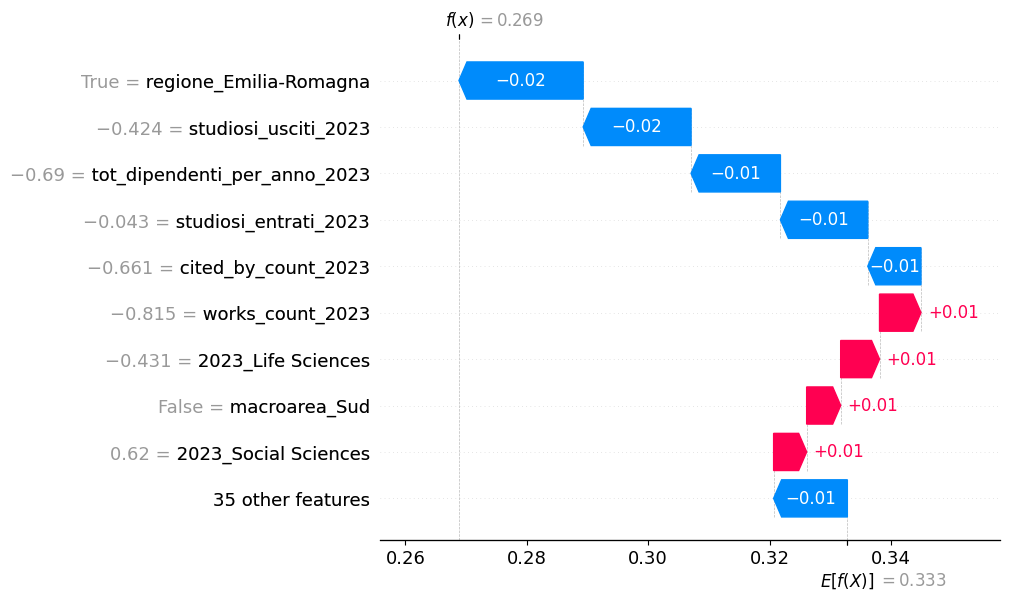

In [ ]:
for i in range(n_classes):
    shap.waterfall_plot(shap_values_nocity[0, :, i])

4.2 Ri allenamento modello no city

In [ ]:
# Estrai i valori dall'oggetto Explanation
shap_vals = shap_values_nocity.values  # shape: (n_samples, n_features) o (n_samples, n_features, n_classes)

# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
if shap_vals.ndim == 3:
    shap_importance_nocity = np.abs(shap_vals).mean(axis=0).mean(axis=1)
else:
    shap_importance_nocity = np.abs(shap_vals).mean(axis=0)

top_20_idx_nocity = np.argsort(shap_importance_nocity)[::-1][:20]
top20_features_nocity = np.array(x_val.columns)[top_20_idx_nocity]
print(top20_features_nocity.tolist())

['tot_dipendenti_per_anno_2023', 'cited_by_count_2023', 'studiosi_usciti_2023', '2023_Health Sciences', 'works_count_2023', 'studiosi_entrati_2023', '2023_Physical Sciences', '2023_Life Sciences', '2023_Social Sciences', 'regione_Lombardy', 'type_company', 'regione_Lazio', 'regione_Emilia-Romagna', 'macroarea_Nord', 'type_healthcare', 'macroarea_Centro', 'type_facility', 'macroarea_Sud', 'type_education', 'regione_Tuscany']


In [ ]:
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10],         
    'min_samples_split': [5, 10, 20], 
    'min_samples_leaf': [4, 8, 16],   
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced']
}

rf_grid = RandomizedSearchCV(RandomForestClassifier(),
                       rf_params, 
                       cv = 5,
                       verbose = 1,
                       n_jobs = -1, 
                       scoring = 'f1_weighted')

In [ ]:
new_x_train = x_train[top20_features_nocity]
new_x_val = x_val[top20_features_nocity]

In [ ]:
rf_grid.fit(new_x_train, y_train)
print(rf_grid.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
{'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced'}


In [ ]:
rf_no_city = RandomForestClassifier(**rf_grid.best_params_, random_state=42)
rf_no_city.fit(new_x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [ ]:
y_pred_no_city = rf_no_city.predict(new_x_val)
print('Classification Report per Random Forest')
print(classification_report(y_val, y_pred_no_city))
print(f'Accuracy della Random Forest: {accuracy_score(y_val, y_pred_no_city)}')
print(f'F1 Score della Random Forest: {f1_score(y_val, y_pred_no_city, average="weighted")}')

Classification Report per Random Forest
              precision    recall  f1-score   support

           0       0.19      0.52      0.28        25
           1       0.41      0.57      0.47        69
           2       0.82      0.40      0.53       136

    accuracy                           0.46       230
   macro avg       0.47      0.49      0.43       230
weighted avg       0.63      0.46      0.49       230

Accuracy della Random Forest: 0.4608695652173913
F1 Score della Random Forest: 0.48834913224842824


5.2 Evaluation

In [ ]:
y_pred_no_city = rf_no_city.predict(x_test_no_city[top20_features_nocity])
    
test_accuracy = accuracy_score(y_test_no_city, y_pred_no_city)
test_f1_weighted = f1_score(y_test_no_city, y_pred_no_city, average='weighted')
test_f1_macro = f1_score(y_test_no_city, y_pred_no_city, average='macro')
    

print(classification_report(y_test_no_city, y_pred_no_city, 
                                  target_names=lab_encoder.classes_))
print('*' * 50)

              precision    recall  f1-score   support

      inflow       0.29      0.74      0.41        43
     outflow       0.43      0.55      0.48       115
      stable       0.80      0.45      0.57       226

    accuracy                           0.51       384
   macro avg       0.51      0.58      0.49       384
weighted avg       0.63      0.51      0.53       384

**************************************************
